# Homework 5

## Setup
### Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
pd.options.display.float_format = '{:.6f}'.format

figure_directory = Path('figures')
figure_directory.mkdir(exist_ok=True)

### Training Settings

In [ ]:
epochs = 5000
learning_rates = [0.1, 0.01, 0.001, 0.0001]
report_interval = 500
random_seed = 42

print('Epochs:', epochs)
print('Learning Rates:', learning_rates)
print('Report Every:', report_interval, 'epochs')

Epochs: 5000
Learning Rates: [0.1, 0.01, 0.001, 0.0001]
Report Every: 500 epochs


## Problem 1
### Load Temperature Dataset

In [ ]:
t_u = np.array([35.7, 55.9, 58.2, 81.9, 56.3, 48.9,
                33.9, 21.8, 48.4, 60.4, 68.4], dtype=float)
t_c = np.array([0.5, 14.0, 15.0, 28.0, 11.0, 8.0,
                3.0, -4.0, 6.0, 13.0, 21.0], dtype=float)

temperature_data = pd.DataFrame({'t_u': t_u, 't_c': t_c})
display(temperature_data)

,t_u,t_c
0,35.700000,0.500000
1,55.900000,14.000000
2,58.200000,15.000000
3,81.900000,28.000000
4,56.300000,11.000000
5,48.900000,8.000000
6,33.900000,3.000000
7,21.800000,-4.000000
8,48.400000,6.000000
9,60.400000,13.000000


### Normalize Input Data

In [ ]:
t_u_mean = np.mean(t_u)
t_u_std = np.std(t_u)
t_un = (t_u - t_u_mean) / t_u_std

print('Input Mean:', t_u_mean)
print('Input Standard Deviation:', t_u_std)
print('Normalized Input:', t_un)

Input Mean: 51.8
Input Standard Deviation: 16.048619311896644
Normalized Input: [-1.003202  0.255474  0.398788  1.875551  0.280398 -0.180701 -1.115361
 -1.86932  -0.211856  0.535872  1.034357]


### Nonlinear Regression Model

In [ ]:
def nonlinear_model(x, w2, w1, b):
    return w2 * x ** 2 + w1 * x + b

### Cost Function

In [ ]:
def nonlinear_cost(x, y, w2, w1, b):
    m = len(y)
    y_pred = nonlinear_model(x, w2, w1, b)
    error = y_pred - y
    cost = np.sum(error ** 2) / (2 * m)
    return cost

### Gradient Descent Function

In [ ]:
def nonlinear_gradient_descent(x, y, learning_rate, iterations):
    m = len(y)
    w2 = 0.0
    w1 = 0.0
    b = 0.0
    cost_history = []

    for i in range(iterations):
        y_pred = nonlinear_model(x, w2, w1, b)
        error = y_pred - y

        gradient_w2 = np.sum(error * x ** 2) / m
        gradient_w1 = np.sum(error * x) / m
        gradient_b = np.sum(error) / m

        w2 = w2 - learning_rate * gradient_w2
        w1 = w1 - learning_rate * gradient_w1
        b = b - learning_rate * gradient_b

        cost = nonlinear_cost(x, y, w2, w1, b)
        if not np.isfinite(cost):
            raise FloatingPointError(f'Nonlinear cost diverged at epoch {i+1}.')
        cost_history.append(cost)

    return w2, w1, b, cost_history

### Learning Rate Evaluation

In [ ]:
nonlinear_parameters = []
nonlinear_costs = []
problem1_rows = []

for learning_rate in learning_rates:
    w2, w1, b, cost_history = nonlinear_gradient_descent(
        t_un, t_c, learning_rate, epochs
    )
    nonlinear_parameters.append((w2, w1, b))
    nonlinear_costs.append(cost_history)

    for epoch in range(report_interval, epochs + 1, report_interval):
        problem1_rows.append({
            'Learning Rate': learning_rate,
            'Epoch': epoch,
            'Training Loss': cost_history[epoch - 1]
        })

    print(f'Learning Rate = {learning_rate}')
    print(f'w2 = {w2:.6f}, w1 = {w1:.6f}, b = {b:.6f}')
    print(f'Final Cost = {cost_history[-1]:.6f}\n')

problem1_results = pd.DataFrame(problem1_rows)
display(problem1_results.pivot(index='Epoch', columns='Learning Rate', values='Training Loss'))
problem1_results.to_csv('problem1_loss_every_500_epochs.csv', index=False)

Learning Rate = 0.1
w2 = 0.729001, w1 = 8.679686, b = 9.770999
Final Cost = 1.045360

Learning Rate = 0.01
w2 = 0.729001, w1 = 8.679686, b = 9.770999
Final Cost = 1.045360

Learning Rate = 0.001
w2 = 0.988732, w1 = 8.663709, b = 9.231969
Final Cost = 1.138252

Learning Rate = 0.0001
w2 = 2.458481, w1 = 3.449696, b = 3.460618
Final Cost = 28.390721



Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,80.156693,28.375834,1.137088,1.045360
1000,69.304959,12.744644,1.045884,1.045360
1500,60.505836,6.597423,1.045363,1.045360
2000,53.287284,3.847409,1.045360,1.045360
2500,47.295692,2.531519,1.045360,1.045360
3000,42.265152,1.864725,1.045360,1.045360
3500,37.994814,1.510008,1.045360,1.045360
4000,34.332162,1.314006,1.045360,1.045360
4500,31.160678,1.202683,1.045360,1.045360


### Learning Rate Comparison

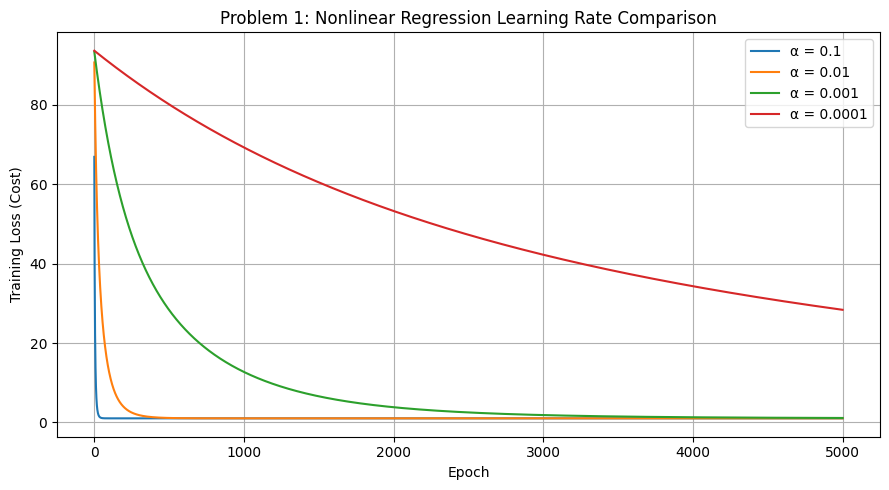

In [ ]:
plt.figure(figsize=(9, 5))
for i, learning_rate in enumerate(learning_rates):
    plt.plot(range(1, epochs + 1), nonlinear_costs[i],
             label=f'α = {learning_rate}')
plt.xlabel('Epoch')
plt.ylabel('Training Loss (Cost)')
plt.title('Problem 1: Nonlinear Regression Learning Rate Comparison')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem1_learning_rates.png', dpi=200)
plt.show()

### Best Nonlinear Model

In [ ]:
final_nonlinear_costs = [history[-1] for history in nonlinear_costs]
minimum_nonlinear_cost = min(final_nonlinear_costs)
best_index_nonlinear = next(
    i for i, cost in enumerate(final_nonlinear_costs)
    if cost <= minimum_nonlinear_cost + 1e-10
)
best_rate_nonlinear = learning_rates[best_index_nonlinear]
best_w2, best_w1, best_b = nonlinear_parameters[best_index_nonlinear]
best_nonlinear_cost = final_nonlinear_costs[best_index_nonlinear]

# Convert coefficients to the original input t_u (not normalized z)
original_w2 = best_w2 / t_u_std ** 2
original_w1 = best_w1 / t_u_std - 2 * best_w2 * t_u_mean / t_u_std ** 2
original_b = (best_b - best_w1 * t_u_mean / t_u_std
              + best_w2 * t_u_mean ** 2 / t_u_std ** 2)

print('Best Learning Rate:', best_rate_nonlinear)
print(f'w2 = {best_w2:.8f}, w1 = {best_w1:.8f}, b = {best_b:.8f}')
print(f'w2 = {original_w2:.8f}, w1 = {original_w1:.8f}, b = {original_b:.8f}')
print('Final Nonlinear Cost:', best_nonlinear_cost)

Best Learning Rate: 0.1
w2 = 0.72900093, w1 = 8.67968555, b = 9.77099907
w2 = 0.00283043, w1 = 0.24760414, b = -10.64962402
Final Nonlinear Cost: 1.0453601149665028


### Linear Regression Baseline

In [ ]:
def temperature_linear_model(x, w, b):
    return w * x + b


def temperature_linear_gradient_descent(x, y, learning_rate, iterations):
    m = len(y)
    w = 0.0
    b = 0.0
    cost_history = []

    for i in range(iterations):
        y_pred = temperature_linear_model(x, w, b)
        error = y_pred - y
        gradient_w = np.sum(error * x) / m
        gradient_b = np.sum(error) / m
        w = w - learning_rate * gradient_w
        b = b - learning_rate * gradient_b
        y_pred = temperature_linear_model(x, w, b)
        cost_history.append(np.sum((y_pred-y) ** 2) / (2 * m))

    return w, b, cost_history

linear_w, linear_b, linear_costs = temperature_linear_gradient_descent(
    t_un, t_c, learning_rate=0.1, iterations=epochs
)
linear_final_cost = linear_costs[-1]
print(f'Baseline Linear Model on z: {linear_w:.6f}*z + {linear_b:.6f}')
print('Final Linear Cost:', linear_final_cost)
print('Final Nonlinear Cost:', best_nonlinear_cost)
print('Cost Improvement:', linear_final_cost - best_nonlinear_cost)

Baseline Linear Model on z: 8.614448*z + 10.500000
Final Linear Cost: 1.4638227854478187
Final Nonlinear Cost: 1.0453601149665028
Cost Improvement: 0.4184626704813159


### Linear vs Nonlinear Regression

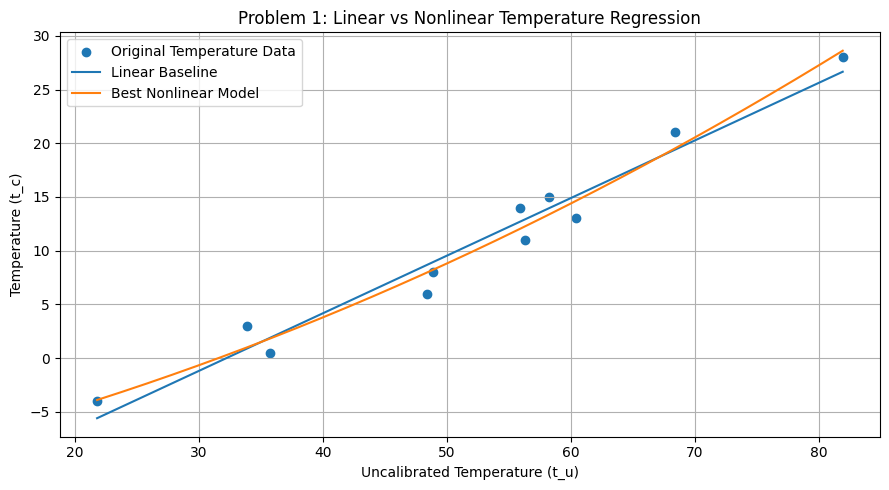

In [ ]:
t_u_plot = np.linspace(t_u.min(), t_u.max(), 300)
z_plot = (t_u_plot - t_u_mean) / t_u_std

plt.figure(figsize=(9, 5))
plt.scatter(t_u, t_c, label='Original Temperature Data')
plt.plot(t_u_plot, temperature_linear_model(z_plot, linear_w, linear_b),
         label='Linear Baseline')
plt.plot(t_u_plot, nonlinear_model(z_plot, best_w2, best_w1, best_b),
         label='Best Nonlinear Model')
plt.xlabel('Uncalibrated Temperature (t_u)')
plt.ylabel('Temperature (t_c)')
plt.title('Problem 1: Linear vs Nonlinear Temperature Regression')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem1_linear_vs_nonlinear.png', dpi=200)
plt.show()

### Results Table

In [ ]:
problem1_summary = pd.DataFrame({
    'Model': ['Linear Baseline', 'Best Nonlinear'],
    'Learning Rate': [0.1, best_rate_nonlinear],
    'Final Training Loss': [linear_final_cost, best_nonlinear_cost]
})
display(problem1_summary)

,Model,Learning Rate,Final Training Loss
0,Linear Baseline,0.100000,1.463823
1,Best Nonlinear,0.100000,1.045360


## Problem 2
### Load Housing Dataset

In [ ]:
from pathlib import Path

housing_path = Path('/content/drive/MyDrive/Colab Notebooks/Housing.csv')
if not housing_path.exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass
if not housing_path.exists():
    housing_path = Path('Housing.csv')

housing_data = pd.read_csv(housing_path)
housing_data.columns = housing_data.columns.str.strip().str.lower()
housing_data = housing_data.dropna().reset_index(drop=True)
housing_data['price'] = pd.to_numeric(housing_data['price'], errors='raise')

print('Dataset shape:', housing_data.shape)
print('Columns:', list(housing_data.columns))
housing_data.head()

Dataset shape: (545, 13)
Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### 80/20 Training/Validation Split

In [ ]:
rng = np.random.default_rng(random_seed)
indices = rng.permutation(len(housing_data))
train_size = int(0.8 * len(indices))
train_indices = indices[:train_size]
validation_indices = indices[train_size:]

train_data = housing_data.iloc[train_indices].copy()
validation_data = housing_data.iloc[validation_indices].copy()

print('Training Samples:', len(train_data))
print('Validation Samples:', len(validation_data))

Training Samples: 436
Validation Samples: 109


### Select Input/Output Variables

In [ ]:
problem2_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']


def preprocess_housing_features(train_frame, validation_frame, feature_names):
    X_train_df = pd.get_dummies(train_frame[feature_names],
                                drop_first=True, dtype=float)
    X_validation_df = pd.get_dummies(validation_frame[feature_names],
                                     drop_first=True, dtype=float)
    X_validation_df = X_validation_df.reindex(columns=X_train_df.columns, fill_value=0)

    X_train = X_train_df.to_numpy(dtype=float)
    X_validation = X_validation_df.to_numpy(dtype=float)

    X_mean = np.mean(X_train, axis=0)
    X_std = np.std(X_train, axis=0)
    X_std[X_std == 0] = 1.0

    X_train_normalized = (X_train - X_mean) / X_std
    X_validation_normalized = (X_validation - X_mean) / X_std

    return (X_train_normalized, X_validation_normalized,
            list(X_train_df.columns), X_mean, X_std)


y_train = train_data['price'].to_numpy(dtype=float)
y_validation = validation_data['price'].to_numpy(dtype=float)
y_mean = np.mean(y_train)
y_std = np.std(y_train)
if y_std == 0:
    raise ValueError('Training target has no variation.')
y_train_normalized = (y_train - y_mean) / y_std
y_validation_normalized = (y_validation - y_mean) / y_std

(X_train_2, X_validation_2, feature_names_2,
 X_mean_2, X_std_2) = preprocess_housing_features(
    train_data, validation_data, problem2_features
)
print('Problem 2 Features:', feature_names_2)
print('Problem 2 Parameter Count:', X_train_2.shape[1] + 1)
print('Training Matrix Shape:', X_train_2.shape)
print('Validation Matrix Shape:', X_validation_2.shape)

Problem 2 Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Problem 2 Parameter Count: 6
Training Matrix Shape: (436, 5)
Validation Matrix Shape: (109, 5)


### Multiple Linear Regression Model

In [ ]:
def multiple_linear_model(X, theta):
    return theta[0] + X @ theta[1:]

### Cost and Validation Functions

In [ ]:
def compute_multiple_cost(X, y, theta):
    m = len(y)
    y_pred = multiple_linear_model(X, theta)
    error = y_pred - y
    return np.sum(error ** 2) / (2 * m)


def r2_score_from_predictions(y_actual, y_predicted):
    denominator = np.sum((y_actual - np.mean(y_actual)) ** 2)
    if denominator == 0:
        return np.nan
    return 1 - np.sum((y_actual - y_predicted) ** 2) / denominator


def regression_metrics(y_actual, y_predicted):
    return {
        'RMSE': np.sqrt(np.mean((y_predicted - y_actual) ** 2)),
        'MAE': np.mean(np.abs(y_predicted - y_actual)),
        'R2': r2_score_from_predictions(y_actual, y_predicted)
    }

### Gradient Descent Function

In [ ]:
def multiple_gradient_descent(X_train, y_train, X_val, y_val,
                              learning_rate, iterations):
    m = len(y_train)
    theta = np.zeros(X_train.shape[1] + 1)
    train_cost_history = []
    validation_cost_history = []
    validation_r2_history = []

    for i in range(iterations):
        y_pred = multiple_linear_model(X_train, theta)
        error = y_pred - y_train

        gradient_b = np.sum(error) / m
        gradient_w = X_train.T @ error / m

        theta[0] = theta[0] - learning_rate * gradient_b
        theta[1:] = theta[1:] - learning_rate * gradient_w

        train_cost = compute_multiple_cost(X_train, y_train, theta)
        validation_cost = compute_multiple_cost(X_val, y_val, theta)
        validation_pred = multiple_linear_model(X_val, theta)
        validation_r2 = r2_score_from_predictions(y_val, validation_pred)

        if not np.isfinite(train_cost) or not np.isfinite(validation_cost):
            raise FloatingPointError(f'Divergence at epoch {i + 1}.')

        train_cost_history.append(train_cost)
        validation_cost_history.append(validation_cost)
        validation_r2_history.append(validation_r2)

    return theta, train_cost_history, validation_cost_history, validation_r2_history

### Learning Rate Evaluation

In [ ]:
def run_housing_training(X_train, X_val, y_train_norm, y_val_norm):
    training_parameters = []
    training_histories = []
    rows = []

    for learning_rate in learning_rates:
        theta, train_cost, val_cost, val_r2 = multiple_gradient_descent(
            X_train, y_train_norm, X_val, y_val_norm,
            learning_rate, epochs
        )
        training_parameters.append(theta)
        training_histories.append({
            'train_loss': train_cost,
            'validation_loss': val_cost,
            'validation_r2': val_r2
        })
        print(f'Learning Rate = {learning_rate}')
        print('Theta =', theta)
        print(f'Final Training Loss = {train_cost[-1]:.6f}')
        print(f'Final Validation Loss = {val_cost[-1]:.6f}')
        print(f'Final Validation R² = {val_r2[-1]:.6f}\n')

        for epoch in range(report_interval, epochs + 1, report_interval):
            rows.append({
                'Learning Rate': learning_rate,
                'Epoch': epoch,
                'Training Loss': train_cost[epoch-1],
                'Validation Loss': val_cost[epoch-1],
                'Validation R²': val_r2[epoch-1],
                'Validation R² (%)': 100 * val_r2[epoch-1]
            })

    results = pd.DataFrame(rows)
    best_index = int(np.argmin([h['validation_loss'][-1]
                                for h in training_histories]))
    return training_parameters, training_histories, results, best_index


(problem2_thetas, problem2_histories,
 problem2_results, best_index_2) = run_housing_training(
    X_train_2, X_validation_2, y_train_normalized, y_validation_normalized
)

print('TRAINING LOSS — Every 500 Epochs')
display(problem2_results.pivot(index='Epoch', columns='Learning Rate',
                               values='Training Loss'))
print('VALIDATION LOSS — Every 500 Epochs')
display(problem2_results.pivot(index='Epoch', columns='Learning Rate',
                               values='Validation Loss'))
print('VALIDATION ACCURACY (R² %) — Every 500 Epochs')
display(problem2_results.pivot(index='Epoch', columns='Learning Rate',
                               values='Validation R² (%)'))
problem2_results.to_csv('problem2_losses_and_validation_every_500_epochs.csv', index=False)

Learning Rate = 0.1
Theta = [-0.        0.385837  0.055734  0.334464  0.251493  0.155949]
Final Training Loss = 0.222170
Final Validation Loss = 0.215670
Final Validation R² = 0.574264

Learning Rate = 0.01
Theta = [-0.        0.385837  0.055734  0.334464  0.251493  0.155949]
Final Training Loss = 0.222170
Final Validation Loss = 0.215670
Final Validation R² = 0.574264

Learning Rate = 0.001
Theta = [-0.        0.381391  0.06581   0.330458  0.245806  0.158236]
Final Training Loss = 0.222222
Final Validation Loss = 0.214494
Final Validation R² = 0.576587

Learning Rate = 0.0001
Theta = [-0.        0.183854  0.105681  0.176388  0.130312  0.111039]
Final Training Loss = 0.274832
Final Validation Loss = 0.246044
Final Validation R² = 0.514305

TRAINING LOSS — Every 500 Epochs


Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,0.455450,0.274768,0.222221,0.222170
1000,0.418333,0.235428,0.222170,0.222170
1500,0.387389,0.226920,0.222170,0.222170
2000,0.361571,0.224340,0.222170,0.222170
2500,0.340014,0.223276,0.222170,0.222170
3000,0.321997,0.222757,0.222170,0.222170
3500,0.306925,0.222487,0.222170,0.222170
4000,0.294302,0.222343,0.222170,0.222170
4500,0.283718,0.222264,0.222170,0.222170


VALIDATION LOSS — Every 500 Epochs


Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,0.454234,0.245978,0.214504,0.215670
1000,0.410060,0.209873,0.215619,0.215670
1500,0.373540,0.207171,0.215668,0.215670
2000,0.343364,0.208753,0.215670,0.215670
2500,0.318446,0.210438,0.215670,0.215670
3000,0.297884,0.211762,0.215670,0.215670
3500,0.280931,0.212762,0.215670,0.215670
4000,0.266968,0.213513,0.215670,0.215670
4500,0.255481,0.214075,0.215670,0.215670


VALIDATION ACCURACY (R² %) — Every 500 Epochs


Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,10.333464,51.443670,57.656577,57.426363
1000,19.053626,58.570791,57.436549,57.426363
1500,26.262704,59.104217,57.426825,57.426363
2000,32.219433,58.791855,57.426385,57.426363
2500,37.138340,58.459227,57.426364,57.426363
3000,41.197300,58.197829,57.426363,57.426363
3500,44.543800,58.000458,57.426363,57.426363
4000,47.300126,57.852287,57.426363,57.426363
4500,49.567672,57.741374,57.426363,57.426363


### Learning Rate Comparison

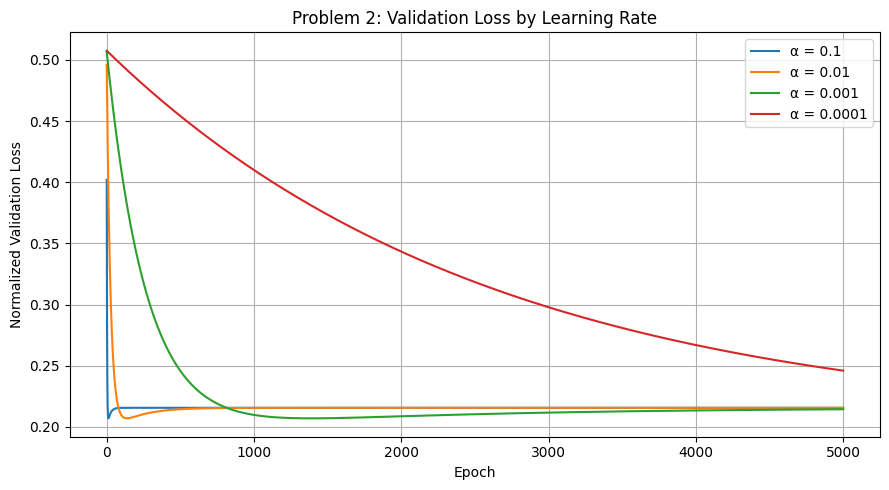

In [ ]:
plt.figure(figsize=(9, 5))
for i, lr in enumerate(learning_rates):
    plt.plot(range(1, epochs+1), problem2_histories[i]['validation_loss'],
             label=f'α = {lr}')
plt.title('Problem 2: Validation Loss by Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Normalized Validation Loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem2_validation_learning_rates.png', dpi=200)
plt.show()

### Best Regression Model

In [ ]:
def original_unit_coefficients(theta, feature_means, feature_stds,
                               price_mean, price_std, feature_names):
    # y = price_mean + price_std * (theta_0 + sum(theta_j * (x_j-mu_j)/std_j))
    original_weights = price_std * theta[1:] / feature_stds
    original_bias = (price_mean + price_std * theta[0]
                     - np.sum(original_weights * feature_means))
    return pd.DataFrame({
        'Parameter': ['Intercept'] + feature_names,
        'Standardized Weight': list(theta),
        'Original Price Units': [original_bias] + list(original_weights)
    })


best_rate_2 = learning_rates[best_index_2]
best_theta_2 = problem2_thetas[best_index_2]
best_validation_loss_2 = problem2_histories[best_index_2]['validation_loss'][-1]
pred_2 = multiple_linear_model(X_validation_2, best_theta_2) * y_std + y_mean
metrics_2 = regression_metrics(y_validation, pred_2)
parameters_2 = original_unit_coefficients(
    best_theta_2, X_mean_2, X_std_2, y_mean, y_std, feature_names_2
)

print('Best Learning Rate:', best_rate_2)
print('Final Training Loss:', problem2_histories[best_index_2]['train_loss'][-1])
print('Final Validation Loss:', best_validation_loss_2)
print('Validation R²:', metrics_2['R2'])
print('Validation RMSE (Original Price Units):', metrics_2['RMSE'])
print('Validation MAE (Original Price Units):', metrics_2['MAE'])
display(parameters_2)
parameters_2.to_csv('problem2_best_parameters.csv', index=False)

Best Learning Rate: 0.001
Final Training Loss: 0.222221614954489
Final Validation Loss: 0.2144935138708655
Validation R²: 0.5765867017244296
Validation RMSE (Original Price Units): 1222143.9635967826
Validation MAE (Original Price Units): 946419.7324113337


,Parameter,Standardized Weight,Original Price Units
0,Intercept,-0.000000,-284308.816313
1,area,0.381391,342.038445
2,bedrooms,0.065810,165744.644752
3,bathrooms,0.330458,1268818.180515
4,stories,0.245806,529752.403161
5,parking,0.158236,339381.050084


### Predicted vs Actual Prices

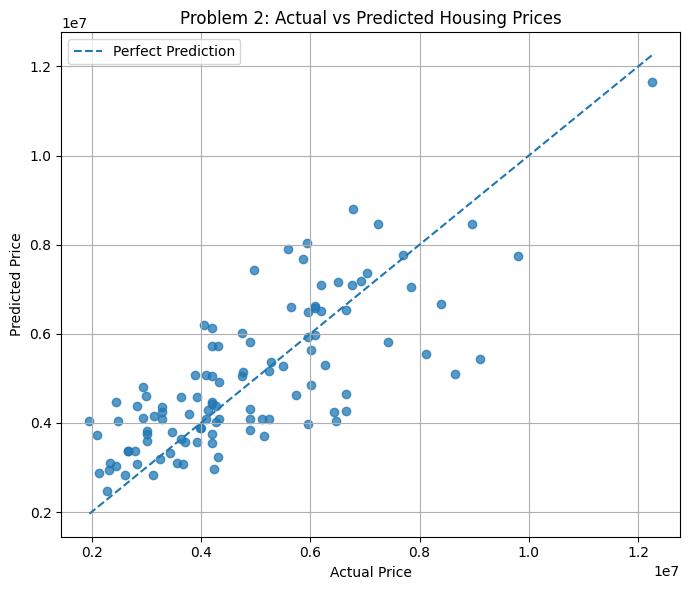

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_validation, pred_2, alpha=0.75)
value_min = min(np.min(y_validation), np.min(pred_2))
value_max = max(np.max(y_validation), np.max(pred_2))
plt.plot([value_min, value_max], [value_min, value_max],
         '--', label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Problem 2: Actual vs Predicted Housing Prices')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem2_actual_vs_predicted.png', dpi=200)
plt.show()

### Results Table

In [ ]:
problem2_final = problem2_results.loc[problem2_results['Epoch'] == epochs].copy()
display(problem2_final)

,Learning Rate,Epoch,Training Loss,Validation Loss,Validation R²,Validation R² (%)
9,0.100000,5000,0.222170,0.215670,0.574264,57.426363
19,0.010000,5000,0.222170,0.215670,0.574264,57.426363
29,0.001000,5000,0.222222,0.214494,0.576587,57.658670
39,0.000100,5000,0.274832,0.246044,0.514305,51.430506


## Problem 3
### Select All Input Features

In [ ]:
problem3_features = [column for column in housing_data.columns if column != 'price']

(X_train_3, X_validation_3, feature_names_3,
 X_mean_3, X_std_3) = preprocess_housing_features(
    train_data, validation_data, problem3_features
)

print('Original Features:', problem3_features)
print('Encoded Features:', feature_names_3)
print('Parameter Count (Bias + Weights):', len(feature_names_3) + 1)
print('Training Matrix Shape:', X_train_3.shape)
print('Validation Matrix Shape:', X_validation_3.shape)

Original Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Encoded Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Parameter Count (Bias + Weights): 14
Training Matrix Shape: (436, 13)
Validation Matrix Shape: (109, 13)


### Learning Rate Evaluation

In [ ]:
(problem3_thetas, problem3_histories,
 problem3_results, best_index_3) = run_housing_training(
    X_train_3, X_validation_3, y_train_normalized, y_validation_normalized
)

print('TRAINING LOSS — Every 500 Epochs')
display(problem3_results.pivot(index='Epoch', columns='Learning Rate',
                               values='Training Loss'))
print('VALIDATION LOSS — Every 500 Epochs')
display(problem3_results.pivot(index='Epoch', columns='Learning Rate',
                               values='Validation Loss'))
print('VALIDATION ACCURACY (R² %) — Every 500 Epochs')
display(problem3_results.pivot(index='Epoch', columns='Learning Rate',
                               values='Validation R² (%)'))
problem3_results.to_csv('problem3_losses_and_validation_every_500_epochs.csv', index=False)

Learning Rate = 0.1
Theta = [-0.        0.290869  0.044053  0.296447  0.195504  0.111403  0.082233
  0.067151  0.048662  0.101131  0.211409  0.177016  0.017497 -0.073779]
Final Training Loss = 0.162969
Final Validation Loss = 0.156354
Final Validation R² = 0.691356

Learning Rate = 0.01
Theta = [-0.        0.290869  0.044053  0.296447  0.195504  0.111403  0.082233
  0.067151  0.048662  0.101131  0.211409  0.177016  0.017497 -0.073779]
Final Training Loss = 0.162969
Final Validation Loss = 0.156354
Final Validation R² = 0.691356

Learning Rate = 0.001
Theta = [-0.        0.286165  0.053534  0.292567  0.19017   0.112364  0.086209
  0.07041   0.045864  0.099882  0.211062  0.175838  0.015947 -0.07543 ]
Final Training Loss = 0.163019
Final Validation Loss = 0.155508
Final Validation R² = 0.693026

Learning Rate = 0.0001
Theta = [-0.        0.162522  0.096414  0.163651  0.119012  0.097177  0.08037
  0.070722  0.044481  0.03936   0.127729  0.104536  0.019122 -0.068427]
Final Training Loss = 0

Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,0.431550,0.203171,0.163019,0.162969
1000,0.377484,0.171436,0.162970,0.162969
1500,0.334742,0.166210,0.162970,0.162969
2000,0.300918,0.164570,0.162969,0.162969
2500,0.274122,0.163821,0.162969,0.162969
3000,0.252865,0.163436,0.162969,0.162969
3500,0.235976,0.163230,0.162969,0.162969
4000,0.222535,0.163117,0.162969,0.162969
4500,0.211815,0.163055,0.162969,0.162969


VALIDATION LOSS — Every 500 Epochs


Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,0.427874,0.171589,0.155518,0.156354
1000,0.365286,0.146069,0.156357,0.156354
1500,0.316210,0.147133,0.156358,0.156354
2000,0.277757,0.149577,0.156354,0.156354
2500,0.247657,0.151475,0.156354,0.156354
3000,0.224123,0.152863,0.156354,0.156354
3500,0.205749,0.153873,0.156354,0.156354
4000,0.191431,0.154604,0.156354,0.156354
4500,0.180298,0.155131,0.156354,0.156354


VALIDATION ACCURACY (R² %) — Every 500 Epochs


Learning Rate,0.000100,0.001000,0.010000,0.100000
Epoch,,,,
500,15.537018,66.128156,69.300491,69.135570
1000,27.891992,71.165710,69.134905,69.135570
1500,37.579785,70.955710,69.134667,69.135570
2000,45.170405,70.473290,69.135435,69.135570
2500,51.112205,70.098518,69.135554,69.135570
3000,55.757860,69.824553,69.135569,69.135570
3500,59.384790,69.625284,69.135570,69.135570
4000,62.211221,69.480913,69.135570,69.135570
4500,64.408816,69.376937,69.135570,69.135570


### Learning Rate Comparison

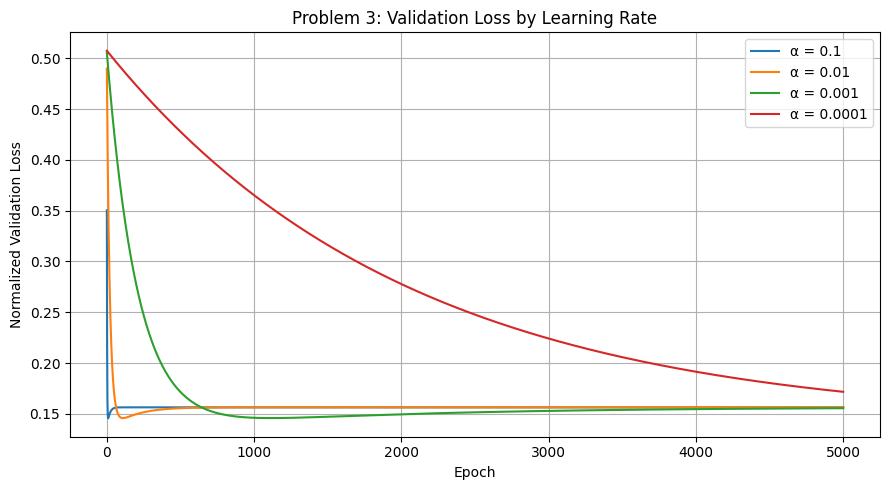

In [ ]:
plt.figure(figsize=(9, 5))
for i, lr in enumerate(learning_rates):
    plt.plot(range(1, epochs+1), problem3_histories[i]['validation_loss'],
             label=f'α = {lr}')
plt.title('Problem 3: Validation Loss by Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Normalized Validation Loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem3_validation_learning_rates.png', dpi=200)
plt.show()

### Best Regression Model

In [ ]:
best_rate_3 = learning_rates[best_index_3]
best_theta_3 = problem3_thetas[best_index_3]
best_validation_loss_3 = problem3_histories[best_index_3]['validation_loss'][-1]
pred_3 = multiple_linear_model(X_validation_3, best_theta_3) * y_std + y_mean
metrics_3 = regression_metrics(y_validation, pred_3)
parameters_3 = original_unit_coefficients(
    best_theta_3, X_mean_3, X_std_3, y_mean, y_std, feature_names_3
)

print('Best Learning Rate:', best_rate_3)
print('Final Training Loss:', problem3_histories[best_index_3]['train_loss'][-1])
print('Final Validation Loss:', best_validation_loss_3)
print('Validation R²:', metrics_3['R2'])
print('Validation RMSE (Original Price Units):', metrics_3['RMSE'])
print('Validation MAE (Original Price Units):', metrics_3['MAE'])
display(parameters_3)
parameters_3.to_csv('problem3_best_parameters.csv', index=False)

Best Learning Rate: 0.001
Final Training Loss: 0.16301938106760422
Final Validation Loss: 0.1555076242210303
Validation R²: 0.6930257009166934
Validation RMSE (Original Price Units): 1040617.5075858269
Validation MAE (Original Price Units): 802106.8021271505


,Parameter,Standardized Weight,Original Price Units
0,Intercept,-0.000000,-229741.542937
1,area,0.286165,256.638332
2,bedrooms,0.053534,134827.383280
3,bathrooms,0.292567,1123333.826747
4,stories,0.190170,409847.360559
5,parking,0.112364,240995.868938
6,mainroad_yes,0.086209,460582.240418
7,guestroom_yes,0.070410,344530.523435
8,basement_yes,0.045864,178531.402600
9,hotwaterheating_yes,0.099882,851452.652874


### Predicted vs Actual Prices

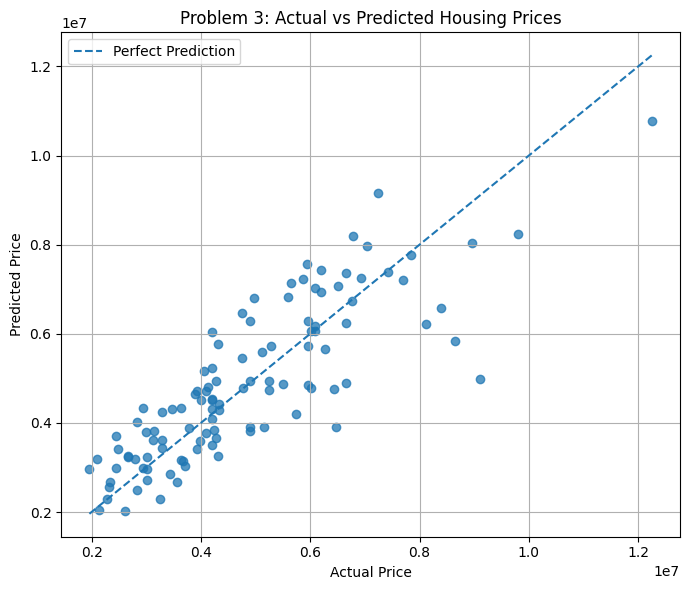

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_validation, pred_3, alpha=0.75)
value_min = min(np.min(y_validation), np.min(pred_3))
value_max = max(np.max(y_validation), np.max(pred_3))
plt.plot([value_min, value_max], [value_min, value_max],
         '--', label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Problem 3: Actual vs Predicted Housing Prices')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem3_actual_vs_predicted.png', dpi=200)
plt.show()

### Results Table

In [ ]:
problem3_final = problem3_results.loc[problem3_results['Epoch'] == epochs].copy()
display(problem3_final)

,Learning Rate,Epoch,Training Loss,Validation Loss,Validation R²,Validation R² (%)
9,0.100000,5000,0.162969,0.156354,0.691356,69.135570
19,0.010000,5000,0.162969,0.156354,0.691356,69.135570
29,0.001000,5000,0.163019,0.155508,0.693026,69.302570
39,0.000100,5000,0.203247,0.171667,0.661126,66.112605


### Problem 2 and Problem 3 Comparison

In [ ]:
housing_comparison = pd.DataFrame({
    'Model': ['Problem 2: Five Features', 'Problem 3: All Features'],
    'Feature Count': [len(feature_names_2), len(feature_names_3)],
    'Best Learning Rate': [best_rate_2, best_rate_3],
    'Validation Loss': [best_validation_loss_2, best_validation_loss_3],
    'Validation RMSE': [metrics_2['RMSE'], metrics_3['RMSE']],
    'Validation MAE': [metrics_2['MAE'], metrics_3['MAE']],
    'Validation R²': [metrics_2['R2'], metrics_3['R2']]
})
display(housing_comparison)
housing_comparison.to_csv('housing_model_comparison.csv', index=False)

,Model,Feature Count,Best Learning Rate,Validation Loss,Validation RMSE,Validation MAE,Validation R²
0,Problem 2: Five Features,5,0.001000,0.214494,1222143.963597,946419.732411,0.576587
1,Problem 3: All Features,13,0.001000,0.155508,1040617.507586,802106.802127,0.693026


### Validation Loss Comparison

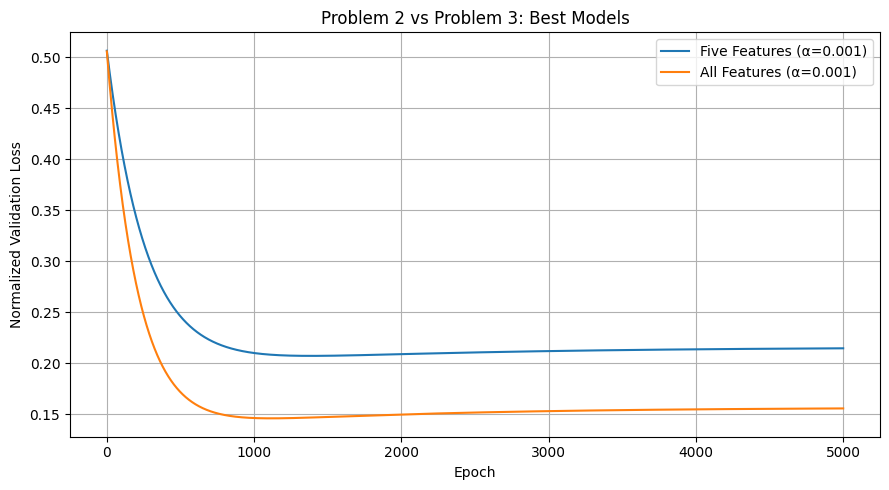

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, epochs + 1),
         problem2_histories[best_index_2]['validation_loss'],
         label=f'Five Features (α={best_rate_2})')
plt.plot(range(1, epochs + 1),
         problem3_histories[best_index_3]['validation_loss'],
         label=f'All Features (α={best_rate_3})')
plt.xlabel('Epoch')
plt.ylabel('Normalized Validation Loss')
plt.title('Problem 2 vs Problem 3: Best Models')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(figure_directory / 'problem2_vs_problem3.png', dpi=200)
plt.show()

### Results Summary

In [ ]:
print('Problem 1')
print('Linear loss:', linear_final_cost)
print('Nonlinear loss:', best_nonlinear_cost)

print('Problem 2')
print('Validation loss:', best_validation_loss_2)
print('Validation R²:', metrics_2['R2'])

print('Problem 3')
print('Validation loss:', best_validation_loss_3)
print('Validation R²:', metrics_3['R2'])

print('Housing comparison:')
display(housing_comparison)

Problem 1
Linear loss: 1.4638227854478187
Nonlinear loss: 1.0453601149665028
Problem 2
Validation loss: 0.2144935138708655
Validation R²: 0.5765867017244296
Problem 3
Validation loss: 0.1555076242210303
Validation R²: 0.6930257009166934
Housing comparison:


,Model,Feature Count,Best Learning Rate,Validation Loss,Validation RMSE,Validation MAE,Validation R²
0,Problem 2: Five Features,5,0.001000,0.214494,1222143.963597,946419.732411,0.576587
1,Problem 3: All Features,13,0.001000,0.155508,1040617.507586,802106.802127,0.693026
